АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.5,  N = 30,  a = 0.5
  κ ∈ [0.1, 8.0],  точек: 80
  Оценочное время ~480 секунд

  10/80  κ=1.000  δ=-8.752e-01+5.143e-01j  (457s, ост: 3199s)
  20/80  κ=2.000  δ=-3.532e-01+4.273e-02j  (901s, ост: 2703s)
  30/80  κ=3.000  δ=-1.692e-01+1.112e-02j  (1338s, ост: 2230s)
  40/80  κ=4.000  δ=-1.028e-01+4.515e-03j  (1767s, ост: 1767s)
  50/80  κ=5.000  δ=-6.785e-02+1.686e-03j  (2193s, ост: 1316s)
  60/80  κ=6.000  δ=-4.848e-02+1.007e-03j  (2606s, ост: 869s)
  70/80  κ=7.000  δ=-3.620e-02+4.531e-04j  (3012s, ост: 430s)
  80/80  κ=8.000  δ=-2.814e-02+3.711e-04j  (3413s, ост: 0s)

Готово за 3412.8 с (42.7 с/точку)
✓ Данные сохранены в afc_data.npz
✓ График сохранён в afc_delta.png


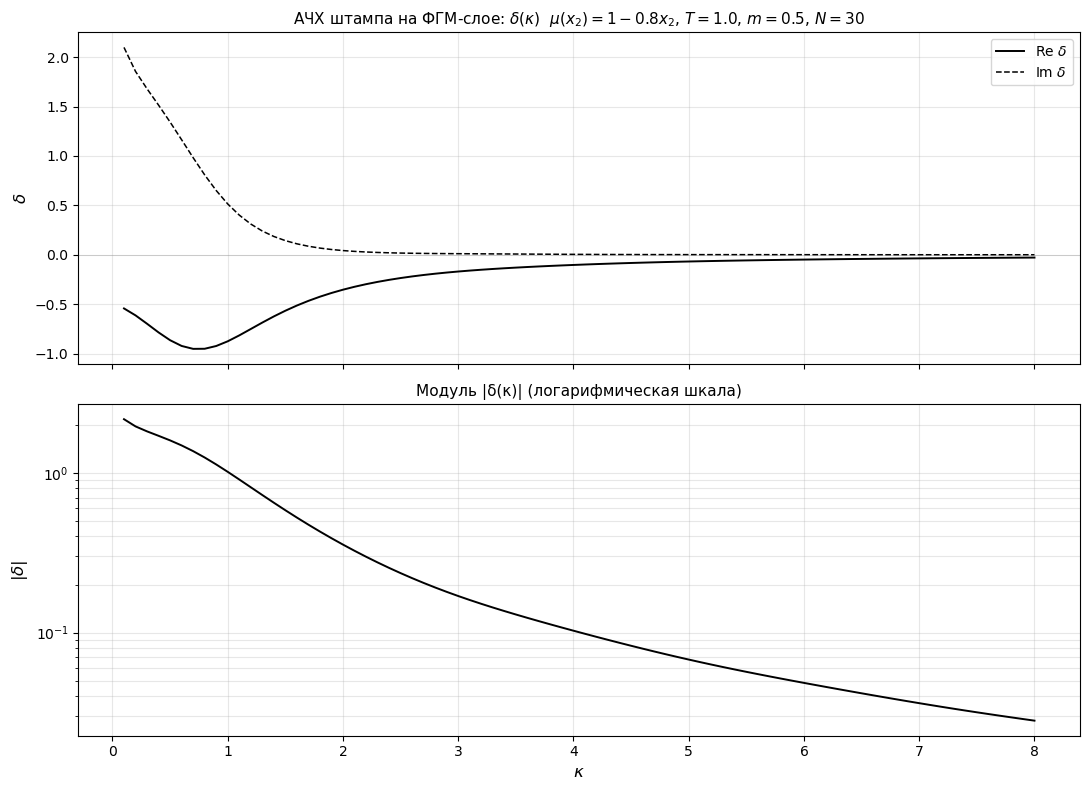

In [5]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.5
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 0.1
    kappa_max = 8.0
    n_kappa = 80
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    np.savez('afc_data.npz',
             kappas=kappas,
             deltas=deltas,
             integrals=integrals,
             T=T, mass=mass, N=N, a_half=a_half)
    print("✓ Данные сохранены в afc_data.npz")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
    plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
    print("✓ График сохранён в afc_delta.png")
    plt.show()


if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 20,  a = 0.5
  κ ∈ [0.1, 8.0],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=1.551  δ=-9.936e-01+5.122e-01j  (305s, ост: 1219s)
  20/50  κ=3.163  δ=-3.977e-01+6.724e-02j  (593s, ост: 889s)
  30/50  κ=4.776  δ=-2.273e-01+1.818e-02j  (878s, ост: 585s)
  40/50  κ=6.388  δ=-1.458e-01+7.954e-03j  (1157s, ост: 289s)
  50/50  κ=8.000  δ=-1.007e-01+4.681e-03j  (1425s, ост: 0s)

Готово за 1425.5 с (28.5 с/точку)
✓ Данные сохранены в afc_data.npz
✓ График сохранён в afc_delta.png


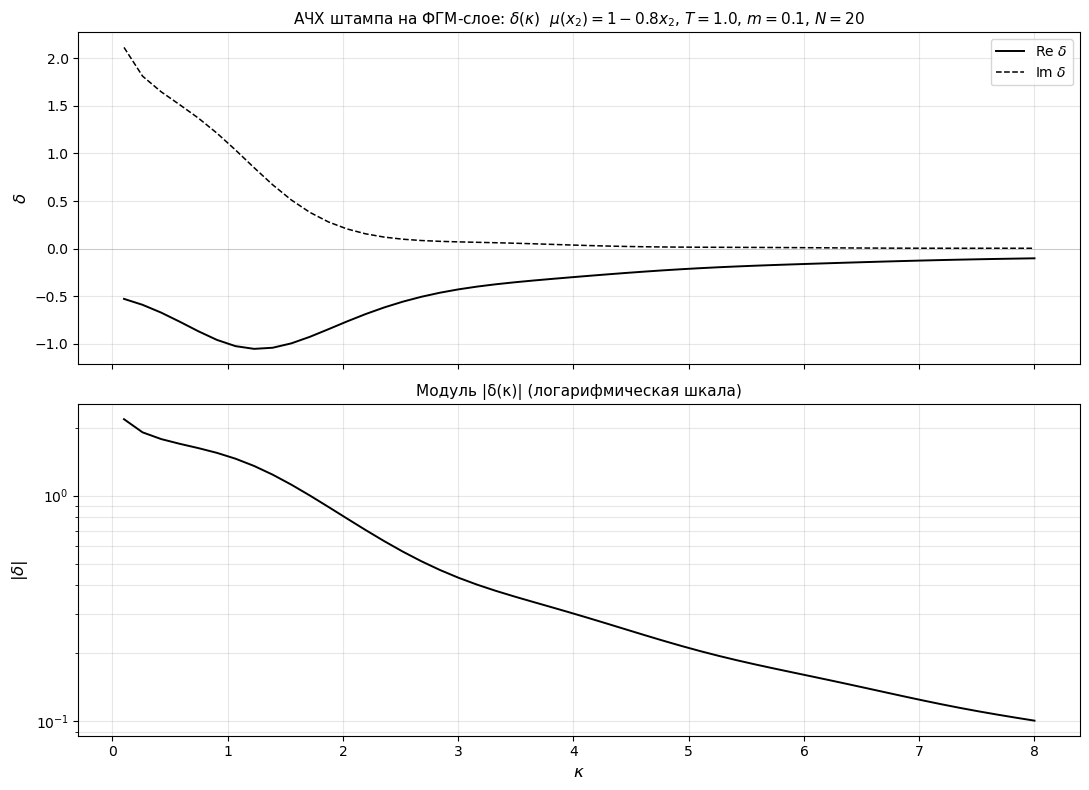

In [6]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 20                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 0.1
    kappa_max = 8.0
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    np.savez('afc_data.npz',
             kappas=kappas,
             deltas=deltas,
             integrals=integrals,
             T=T, mass=mass, N=N, a_half=a_half)
    print("✓ Данные сохранены в afc_data.npz")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
    plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
    print("✓ График сохранён в afc_delta.png")
    plt.show()


if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 40,  a = 0.5
  κ ∈ [2.0, 5.0],  точек: 30
  Оценочное время ~180 секунд

  10/30  κ=2.931  δ=+8.604e-01-2.561e+00j  (680s, ост: 1359s)
  20/30  κ=3.966  δ=-1.605e+00-1.291e+00j  (1346s, ост: 673s)
  30/30  κ=5.000  δ=-9.852e-01-3.590e-01j  (2002s, ост: 0s)

Готово за 2001.9 с (66.7 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data111.txt (открывай её в VS Code)


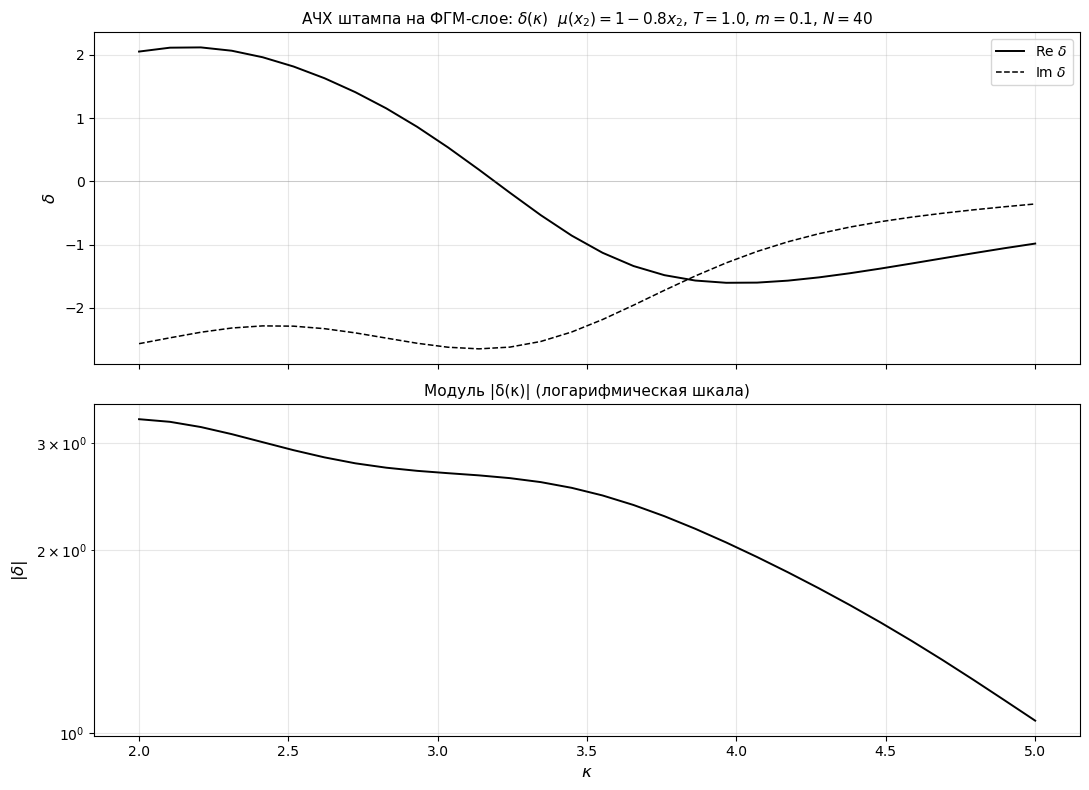

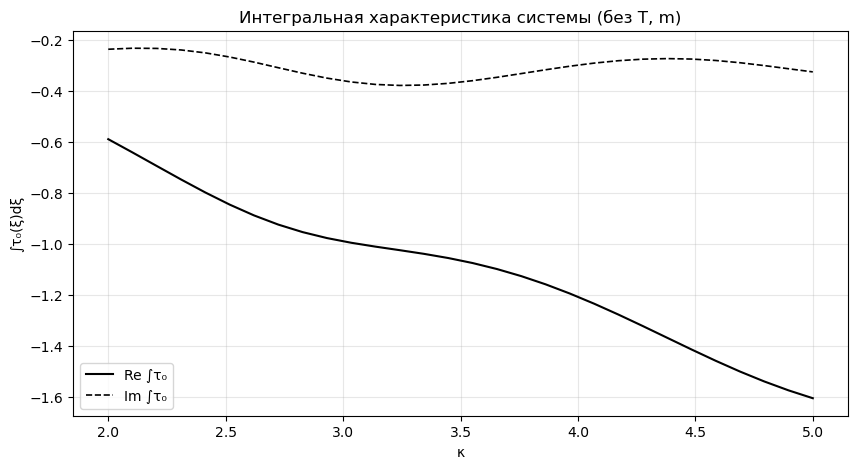

In [11]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.9 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 40                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 2.0
    kappa_max = 5.0
    n_kappa = 30
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data111.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 30,  a = 0.5
  κ ∈ [2.0, 5.0],  точек: 100
  Оценочное время ~600 секунд

  10/100  κ=2.273  δ=+2.092e+00-2.364e+00j  (510s, ост: 4587s)
  20/100  κ=2.576  δ=+1.715e+00-2.331e+00j  (1026s, ост: 4104s)
  30/100  κ=2.879  δ=+1.006e+00-2.540e+00j  (1546s, ост: 3606s)
  40/100  κ=3.182  δ=+1.367e-02-2.654e+00j  (2041s, ост: 3062s)
  50/100  κ=3.485  δ=-9.757e-01-2.313e+00j  (2541s, ост: 2541s)
  60/100  κ=3.788  δ=-1.519e+00-1.647e+00j  (3040s, ост: 2027s)
  70/100  κ=4.091  δ=-1.595e+00-1.064e+00j  (3529s, ост: 1512s)
  80/100  κ=4.394  δ=-1.440e+00-7.033e-01j  (4027s, ост: 1007s)
  90/100  κ=4.697  δ=-1.209e+00-4.955e-01j  (4516s, ост: 502s)
  100/100  κ=5.000  δ=-9.825e-01-3.544e-01j  (5001s, ост: 0s)

Готово за 5001.2 с (50.0 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data222.txt (открывай её в VS Code)


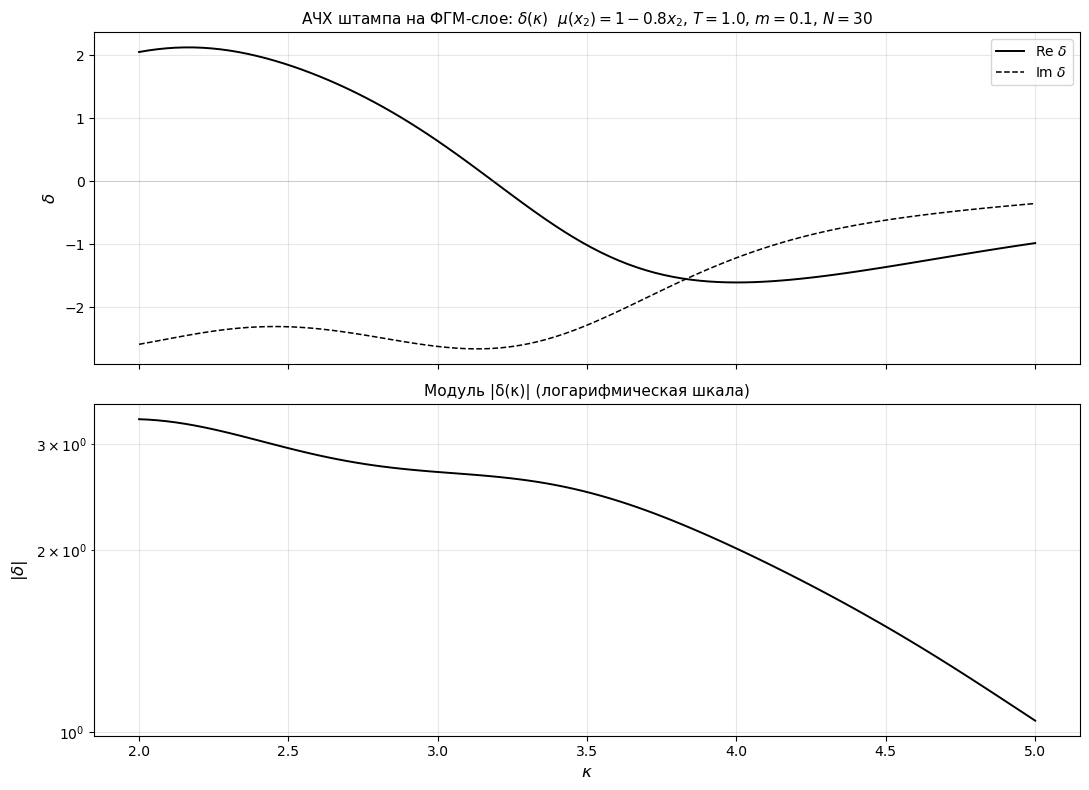

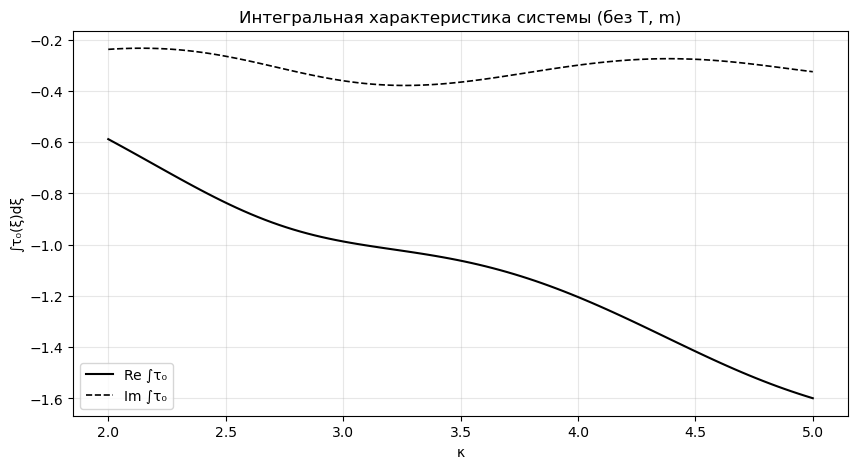

In [13]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.9 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 2.0
    kappa_max = 5.0
    n_kappa = 100
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data222.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 30,  a = 0.5
  κ ∈ [2.0, 8.0],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=3.102  δ=+5.261e-01-2.438e-01j  (344s, ост: 1377s)
  20/50  κ=4.327  δ=+4.815e-01-2.211e-01j  (675s, ост: 1013s)
  30/50  κ=5.551  δ=+5.328e-01-2.695e-01j  (1011s, ост: 674s)
  40/50  κ=6.776  δ=+6.010e-01-4.675e-01j  (1335s, ост: 334s)
  50/50  κ=8.000  δ=+2.483e-01-1.238e+00j  (1661s, ост: 0s)

Готово за 1660.7 с (33.2 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data333.txt (открывай её в VS Code)


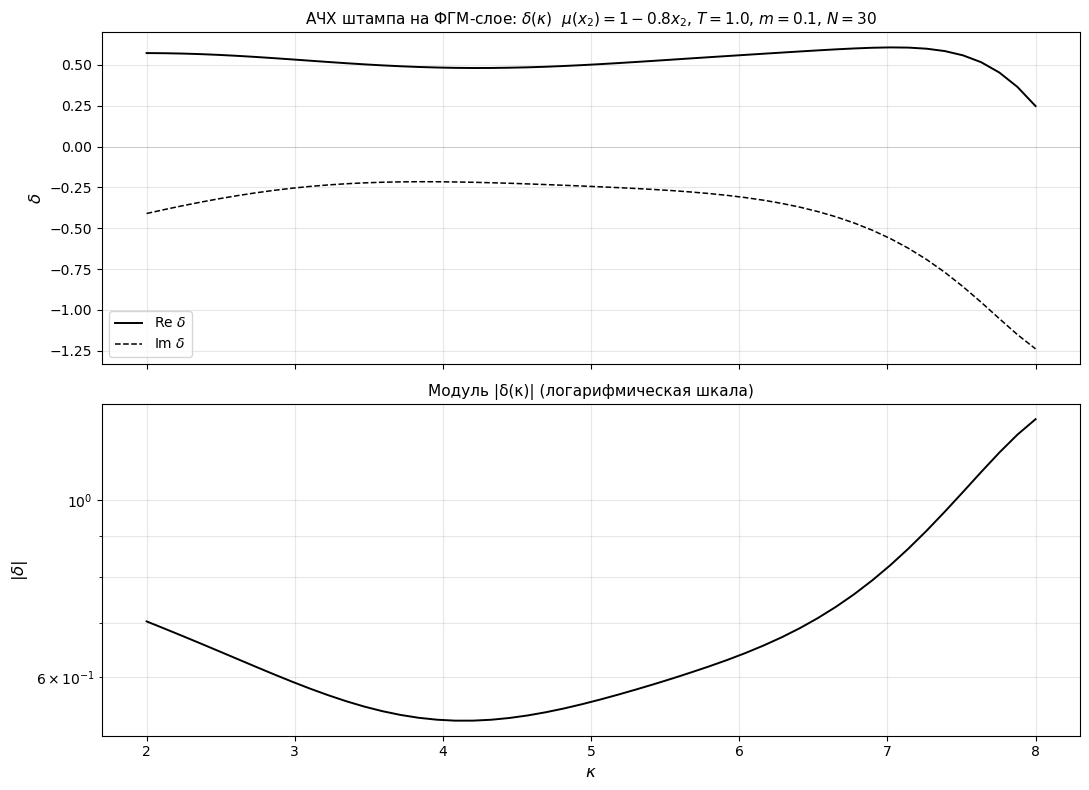

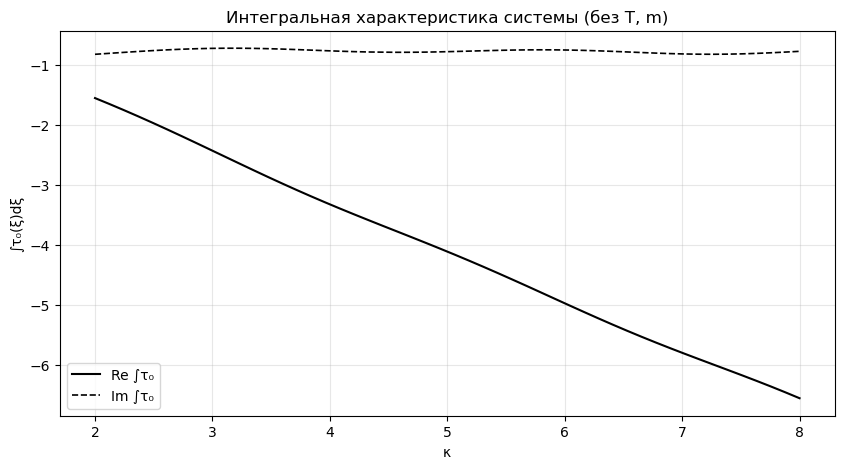

In [14]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.3 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 2.0
    kappa_max = 8.0
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data333.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 30,  a = 0.5
  κ ∈ [6.0, 6.6],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=6.110  δ=-8.071e-01-3.128e-01j  (409s, ост: 1637s)
  20/50  κ=6.233  δ=-7.589e-01-2.587e-01j  (824s, ост: 1235s)
  30/50  κ=6.355  δ=-7.156e-01-2.155e-01j  (1235s, ост: 823s)
  40/50  κ=6.478  δ=-6.766e-01-1.813e-01j  (1641s, ост: 410s)
  50/50  κ=6.600  δ=-6.412e-01-1.547e-01j  (2040s, ост: 0s)

Готово за 2039.8 с (40.8 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data444.txt (открывай её в VS Code)


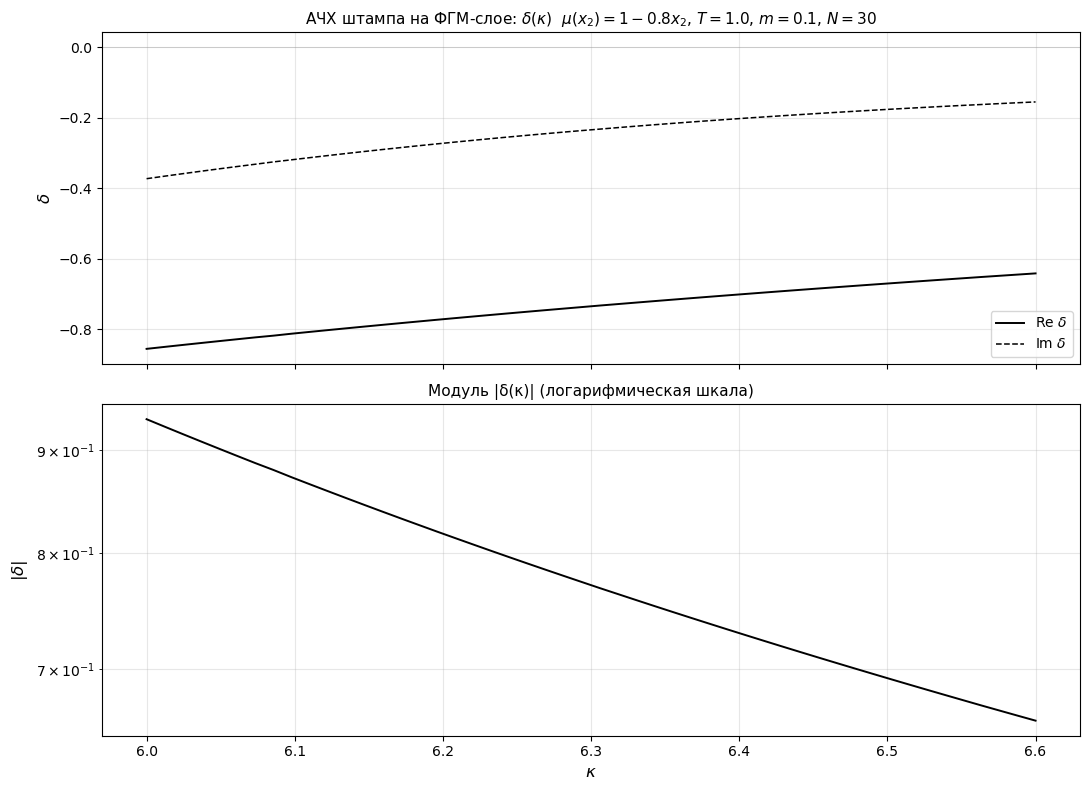

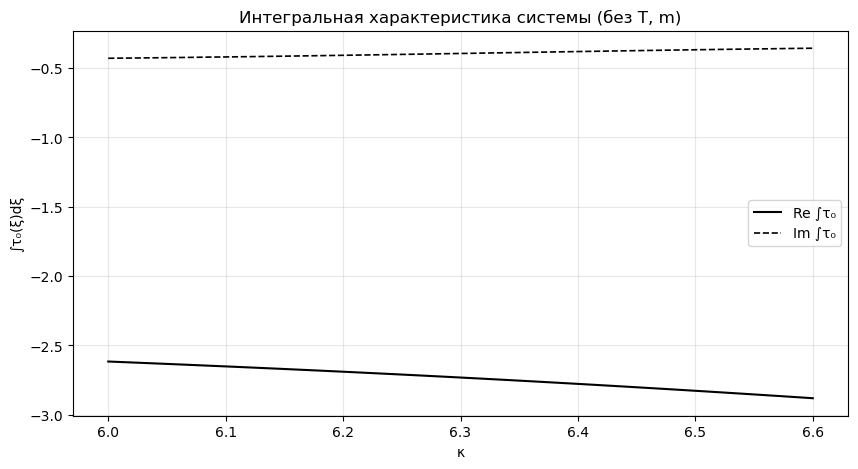

In [5]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 6.0
    kappa_max = 6.6
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data444.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.1,  N = 30,  a = 0.5
  κ ∈ [7.5, 9.0],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=7.776  δ=-3.761e-01-6.663e-02j  (400s, ост: 1599s)
  20/50  κ=8.082  δ=-3.271e-01-5.112e-02j  (797s, ост: 1195s)
  30/50  κ=8.388  δ=-2.895e-01-3.665e-02j  (1196s, ост: 797s)
  40/50  κ=8.694  δ=-2.611e-01-2.546e-02j  (1595s, ост: 399s)
  50/50  κ=9.000  δ=-2.390e-01-1.847e-02j  (1995s, ост: 0s)

Готово за 1995.3 с (39.9 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data555.txt (открывай её в VS Code)


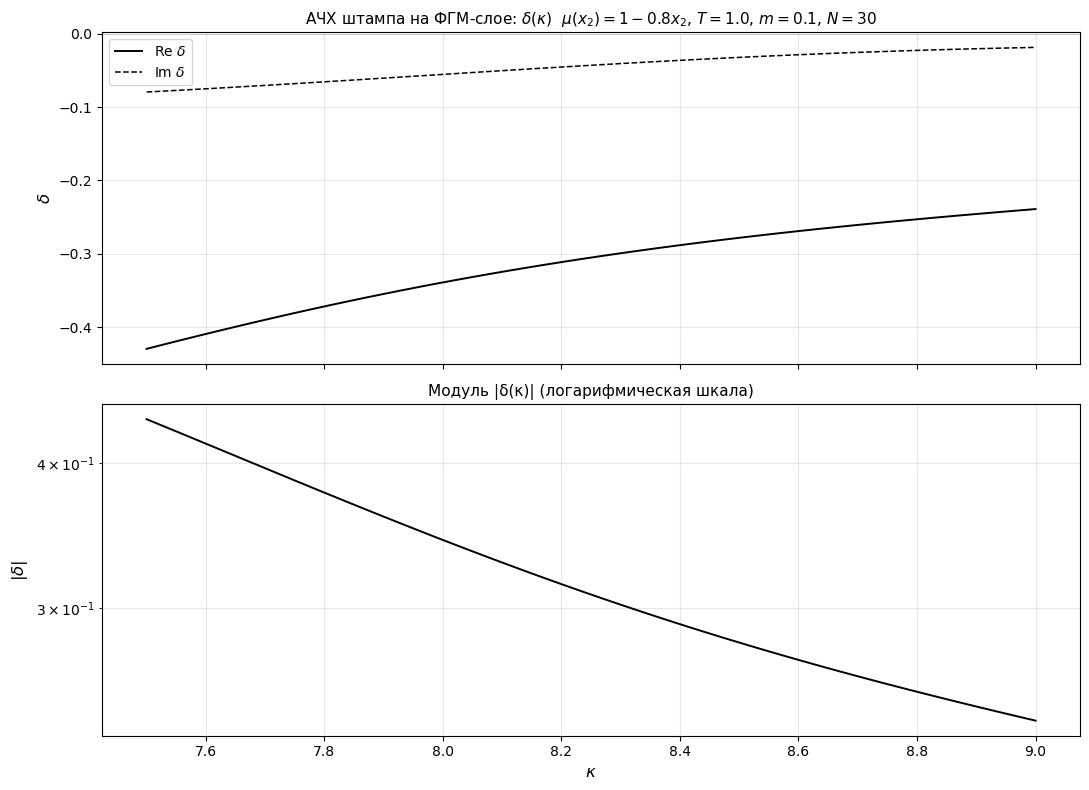

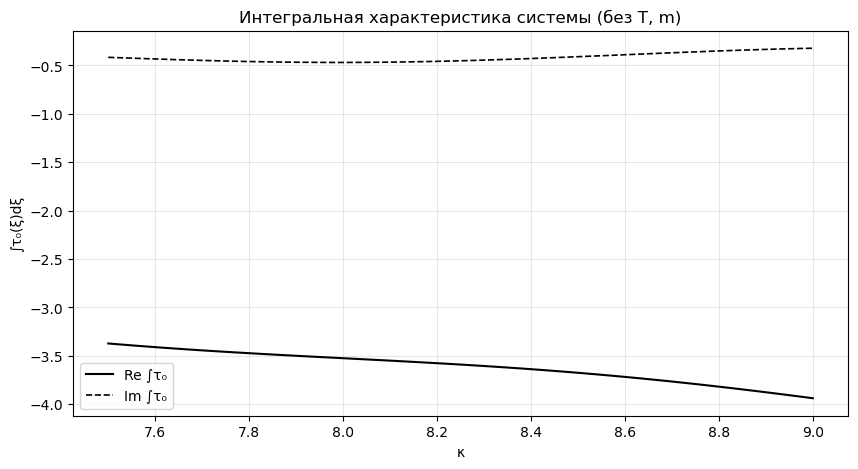

In [6]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.5
    T = 1.0 + 0j
    mass = 0.1
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 7.5
    kappa_max = 9.0
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data555.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.05,  N = 30,  a = 0.1
  κ ∈ [1.5, 10.0],  точек: 80
  Оценочное время ~480 секунд

  10/80  κ=2.468  δ=-1.091e+00-3.326e+00j  (251s, ост: 1756s)
  20/80  κ=3.544  δ=-1.795e+00-1.458e+00j  (481s, ост: 1444s)
  30/80  κ=4.620  δ=-1.277e+00-4.871e-01j  (701s, ост: 1169s)
  40/80  κ=5.696  δ=-8.285e-01-1.849e-01j  (930s, ост: 930s)
  50/80  κ=6.772  δ=-5.687e-01-7.927e-02j  (1166s, ост: 699s)
  60/80  κ=7.848  δ=-4.109e-01-4.062e-02j  (1402s, ост: 467s)
  70/80  κ=8.924  δ=-3.096e-01-2.192e-02j  (1636s, ост: 234s)
  80/80  κ=10.000  δ=-2.417e-01-1.352e-02j  (1863s, ост: 0s)

Готово за 1863.3 с (23.3 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data666.txt (открывай её в VS Code)


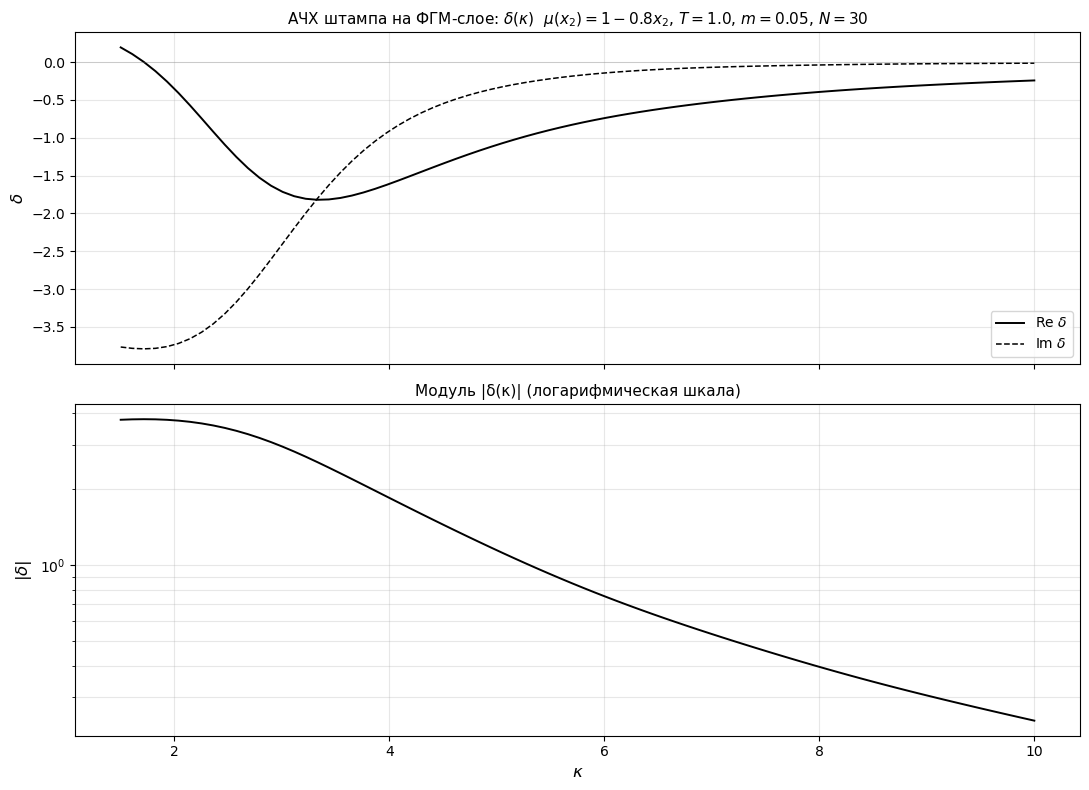

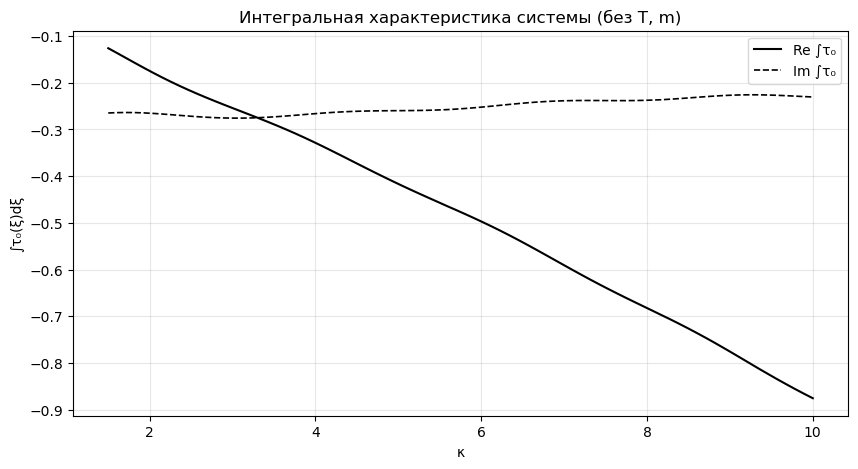

In [9]:
# -*- coding: utf-8 -*-
"""
afc_sweep.py — амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
  1. Создаётся новый FGMLayer и Integral (κ зашит в обоих)
  2. Собирается матрица МГЭ и решается СЛАУ для τ_0
  3. По формуле научника δ = T / (∫τ_0 - m·κ²) считается смещение
  4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ в стиле приведённой картинки.

Время: при N = 20 одно κ ≈ 5-10 секунд, сетка из 80 точек ≈ 7-10 минут.
"""

import math
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz

from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
# Минимальный решатель — копия solve_contact из bem_a, упрощённая
# (без логирования cond, без диагностики, чтобы быстрее)
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

    integral_tau_0 = h * np.sum(tau_0)
    delta = T / (-integral_tau_0 - mass * kappa * kappa)
    return delta, integral_tau_0


# =====================================================================
# Main: сканирование по κ и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.1
    T = 1.0 + 0j
    mass = 0.05
    N = 30                                      # для скорости

    # ---------- Диапазон частот ----------
    kappa_min = 1.5
    kappa_max = 10.0
    n_kappa = 80
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")

    # ---------- Сохраняем числовые данные ----------
    # ---------- Сохраняем числовые данные ----------
    # 1. Бинарный вариант для быстрого импорта обратно в Python (оставляем)
#     np.savez('afc_data.npz',
#              kappas=kappas,
#              deltas=deltas,
#              integrals=integrals,
#              T=T, mass=mass, N=N, a_half=a_half)
#     print("✓ Данные сохранены в бинарный afc_data.npz")

    # 2. Текстовый вариант, который МОЖНО открывать блокнотом
    output_txt = 'afc_data666.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        # Пишем заголовок таблицы
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        # Записываем каждую строчку
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt} (открывай её в VS Code)")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний — Re и Im δ, стиль научника
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний — модуль на лог-шкале (резонансы хорошо видны)
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    
    # В afc_sweep.py после цикла:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.05,  N = 40,  a = 0.1
  κ ∈ [0.5, 7.0],  точек: 100
  Оценочное время ~600 секунд

  10/100  κ=1.091  δ=+3.996e+00+1.704e+00j  (356s, ост: 3207s)
  20/100  κ=1.747  δ=+3.164e+00+4.284e+00j  (701s, ост: 2803s)
  30/100  κ=2.404  δ=-4.023e-01+4.699e+00j  (1035s, ост: 2416s)
  40/100  κ=3.061  δ=-1.843e+00+2.488e+00j  (1355s, ост: 2033s)
  50/100  κ=3.717  δ=-1.552e+00+1.133e+00j  (1659s, ост: 1659s)
  60/100  κ=4.374  δ=-1.131e+00+5.915e-01j  (1956s, ост: 1304s)
  70/100  κ=5.030  δ=-8.462e-01+3.546e-01j  (2259s, ост: 968s)
  80/100  κ=5.687  δ=-6.555e-01+2.285e-01j  (2568s, ост: 642s)
  90/100  κ=6.343  δ=-5.196e-01+1.559e-01j  (2879s, ост: 320s)
  100/100  κ=7.000  δ=-4.218e-01+1.132e-01j  (3198s, ост: 0s)

Готово за 3197.7 с (32.0 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data777.txt


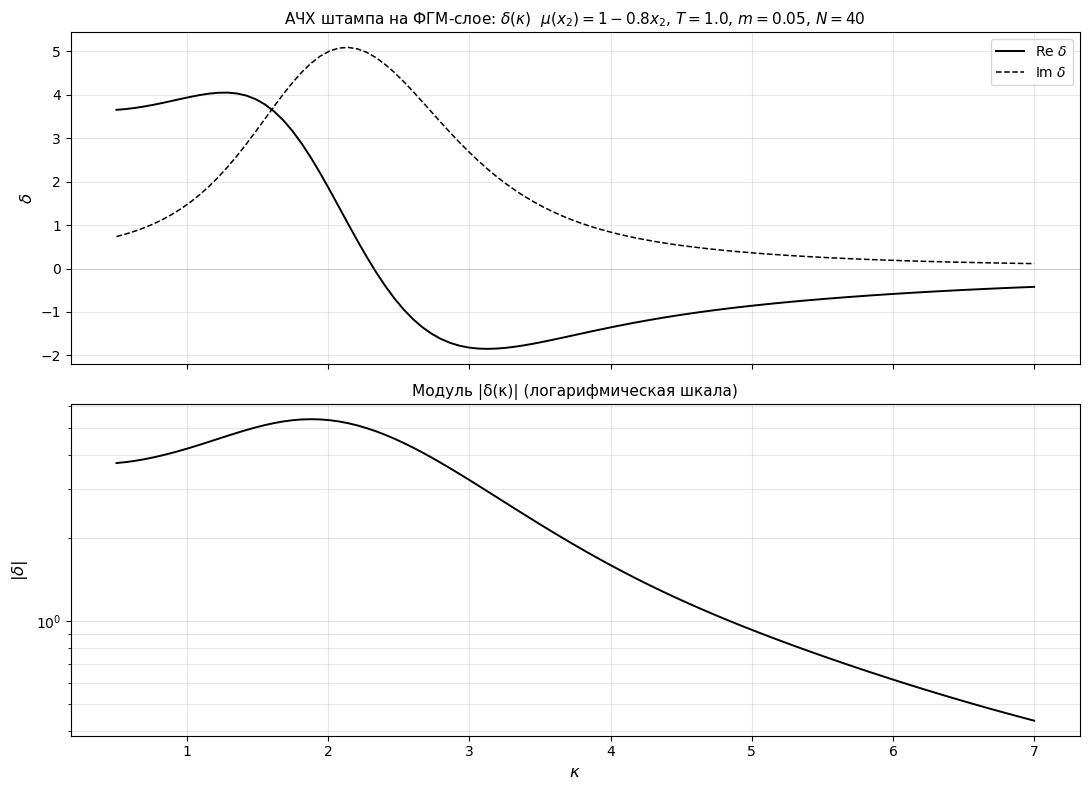

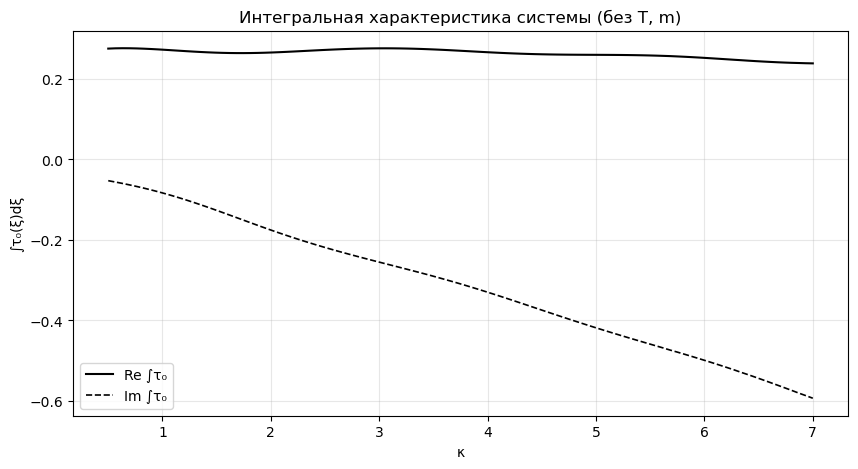

In [2]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-3, n_steps=200, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 0.1
    T = 1.0 + 0j
    mass = 0.05
    N = 40                                      

    # ---------- Диапазон частот ----------
    kappa_min = 0.5
    kappa_max = 7.0
    n_kappa = 100
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data777.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.05,  N = 20,  a = 1.0
  κ ∈ [6.7, 8.2],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=6.976  δ=-4.891e-02+1.456e-01j  (184s, ост: 738s)
  20/50  κ=7.282  δ=-4.538e-02+1.363e-01j  (369s, ост: 553s)
  30/50  κ=7.588  δ=-4.264e-02+1.314e-01j  (549s, ост: 366s)
  40/50  κ=7.894  δ=-4.309e-02+1.282e-01j  (734s, ост: 184s)
  50/50  κ=8.200  δ=-4.609e-02+1.237e-01j  (911s, ост: 0s)

Готово за 910.8 с (18.2 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data777.txt


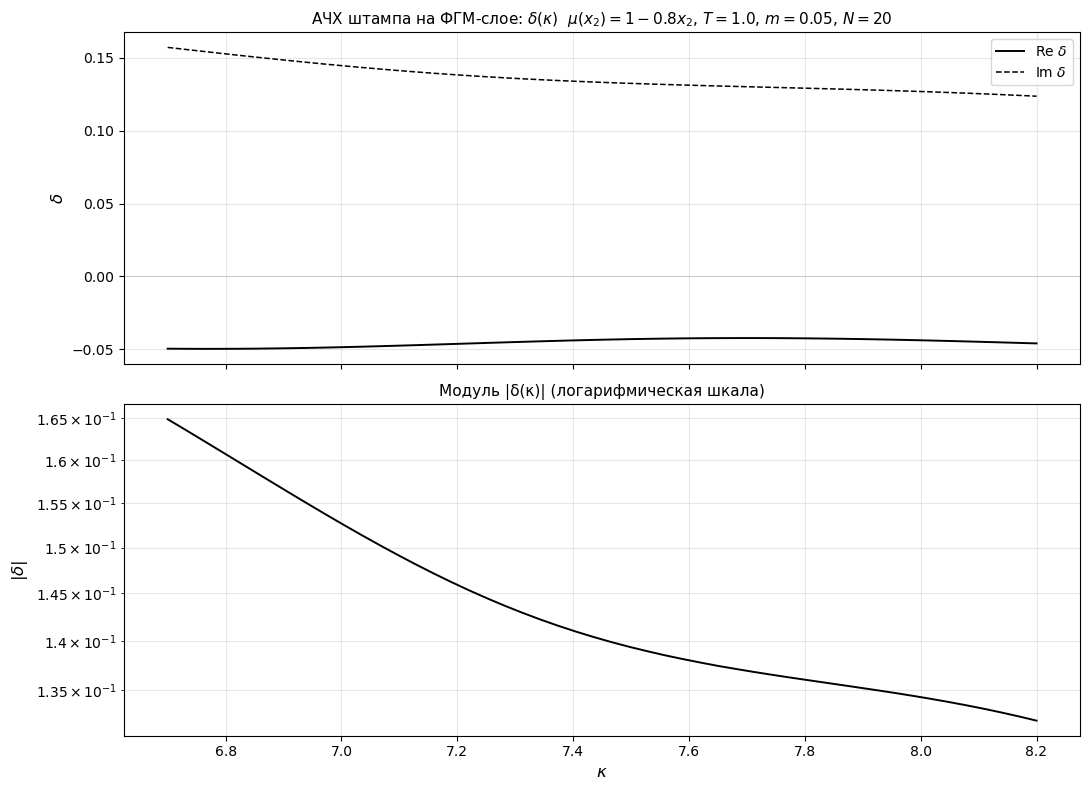

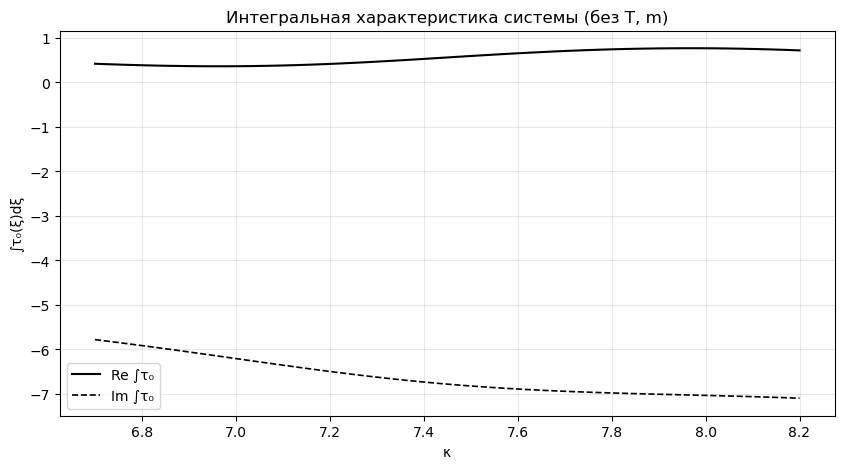

In [1]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=100, n_sub=10):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 1.0
    T = 1.0 + 0j
    mass = 0.05
    N = 20                                      

    # ---------- Диапазон частот ----------
    kappa_min = 6.7
    kappa_max = 8.2
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data777.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.5,  N = 20,  a = 1.0
  κ ∈ [3.7, 4.7],  точек: 30
  Оценочное время ~180 секунд

  10/30  κ=4.010  δ=-1.108e-01+5.106e-02j  (230s, ост: 459s)
  20/30  κ=4.355  δ=-9.486e-02+3.965e-02j  (464s, ост: 232s)
  30/30  κ=4.700  δ=-8.196e-02+3.204e-02j  (691s, ост: 0s)

Готово за 691.4 с (23.0 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data888.txt


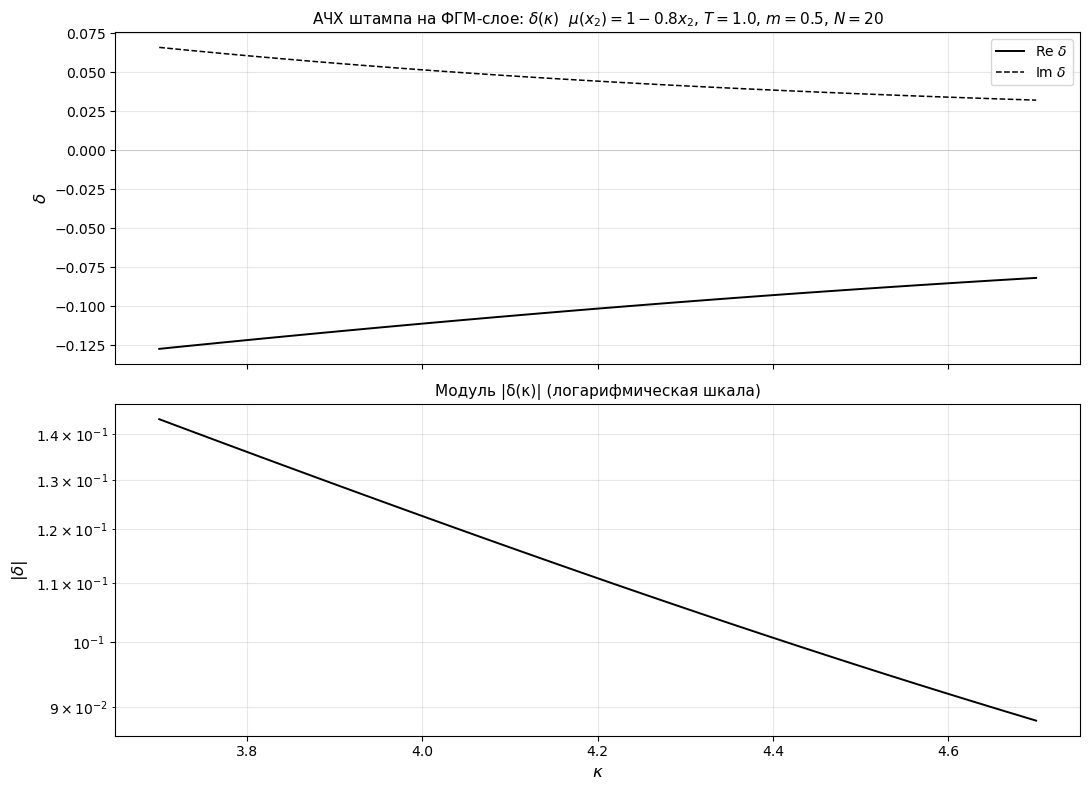

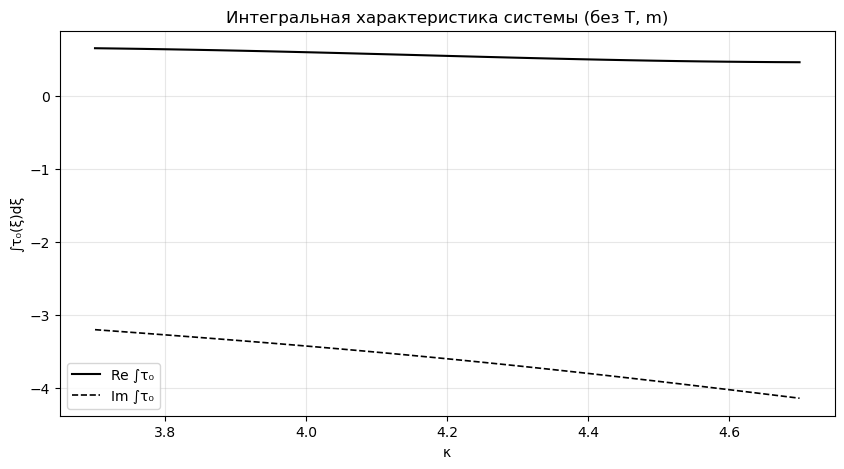

In [1]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=100, n_sub=20):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 1.0
    T = 1.0 + 0j
    mass = 0.5
    N = 20                                      

    # ---------- Диапазон частот ----------
    kappa_min = 3.7
    kappa_max = 4.7
    n_kappa = 30
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data888.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.5,  N = 20,  a = 1.0
  κ ∈ [0.4, 2.5],  точек: 50
  Оценочное время ~300 секунд

  10/50  κ=0.786  δ=+7.182e-01+1.143e+00j  (248s, ост: 991s)
  20/50  κ=1.214  δ=-1.191e-01+1.040e+00j  (493s, ост: 739s)
  30/50  κ=1.643  δ=-3.314e-01+5.483e-01j  (738s, ост: 492s)
  40/50  κ=2.071  δ=-2.790e-01+2.995e-01j  (983s, ост: 246s)
  50/50  κ=2.500  δ=-2.181e-01+1.893e-01j  (1225s, ост: 0s)

Готово за 1225.3 с (24.5 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data999.txt


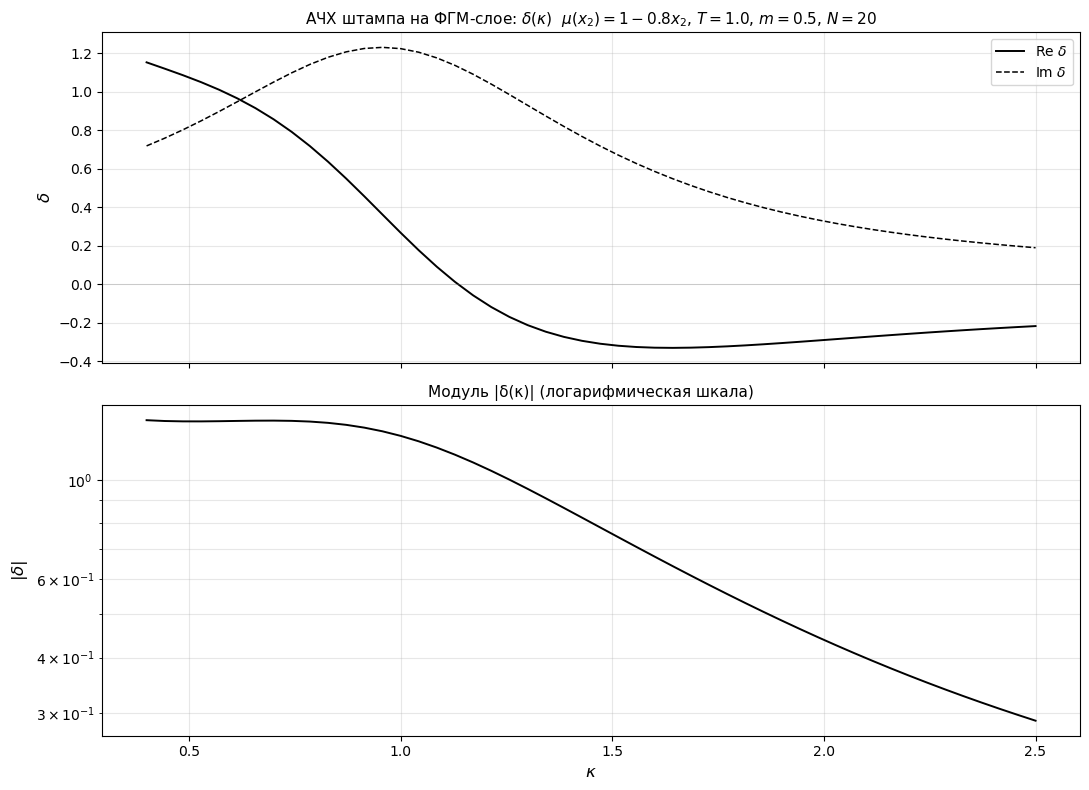

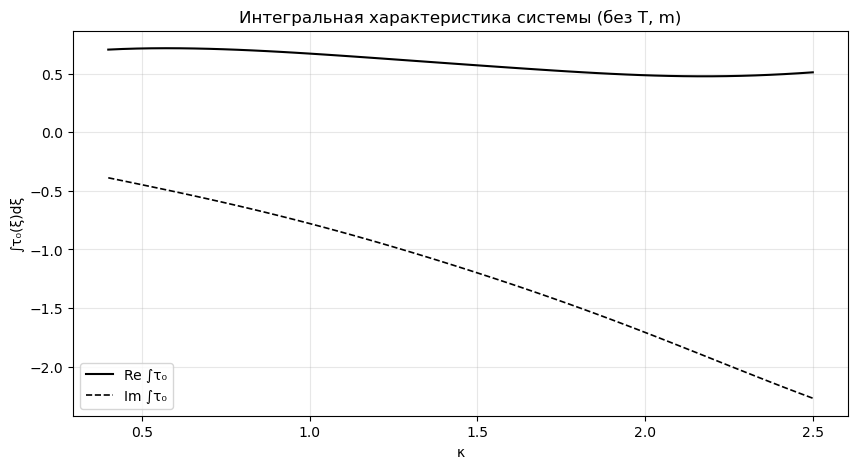

In [2]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=100, n_sub=20):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 1.0
    T = 1.0 + 0j
    mass = 0.5
    N = 20                                      

    # ---------- Диапазон частот ----------
    kappa_min = 0.4
    kappa_max = 2.5
    n_kappa = 50
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data999.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.5,  N = 20,  a = 1.0
  κ ∈ [0.3, 9.0],  точек: 200
  Оценочное время ~1200 секунд

  10/200  κ=0.693  δ=+8.668e-01+1.043e+00j  (241s, ост: 4577s)
  20/200  κ=1.131  δ=+8.039e-03+1.136e+00j  (488s, ост: 4390s)
  30/200  κ=1.568  δ=-3.281e-01+6.167e-01j  (738s, ост: 4180s)
  40/200  κ=2.005  δ=-2.898e-01+3.257e-01j  (983s, ост: 3932s)
  50/200  κ=2.442  δ=-2.250e-01+2.000e-01j  (1226s, ост: 3679s)
  60/200  κ=2.879  δ=-1.822e-01+1.351e-01j  (1468s, ост: 3425s)
  70/200  κ=3.317  δ=-1.511e-01+9.190e-02j  (1708s, ост: 3171s)
  80/200  κ=3.754  δ=-1.244e-01+6.294e-02j  (1947s, ост: 2920s)
  90/200  κ=4.191  δ=-1.021e-01+4.451e-02j  (2179s, ост: 2663s)
  100/200  κ=4.628  δ=-8.440e-02+3.340e-02j  (2410s, ост: 2410s)
  110/200  κ=5.065  δ=-7.134e-02+2.641e-02j  (2642s, ост: 2162s)
  120/200  κ=5.503  δ=-6.178e-02+2.120e-02j  (2872s, ост: 1915s)
  130/200  κ=5.940  δ=-5.406e-02+1.656e-02j  (3101s, ост: 1670s)
  140/200  κ

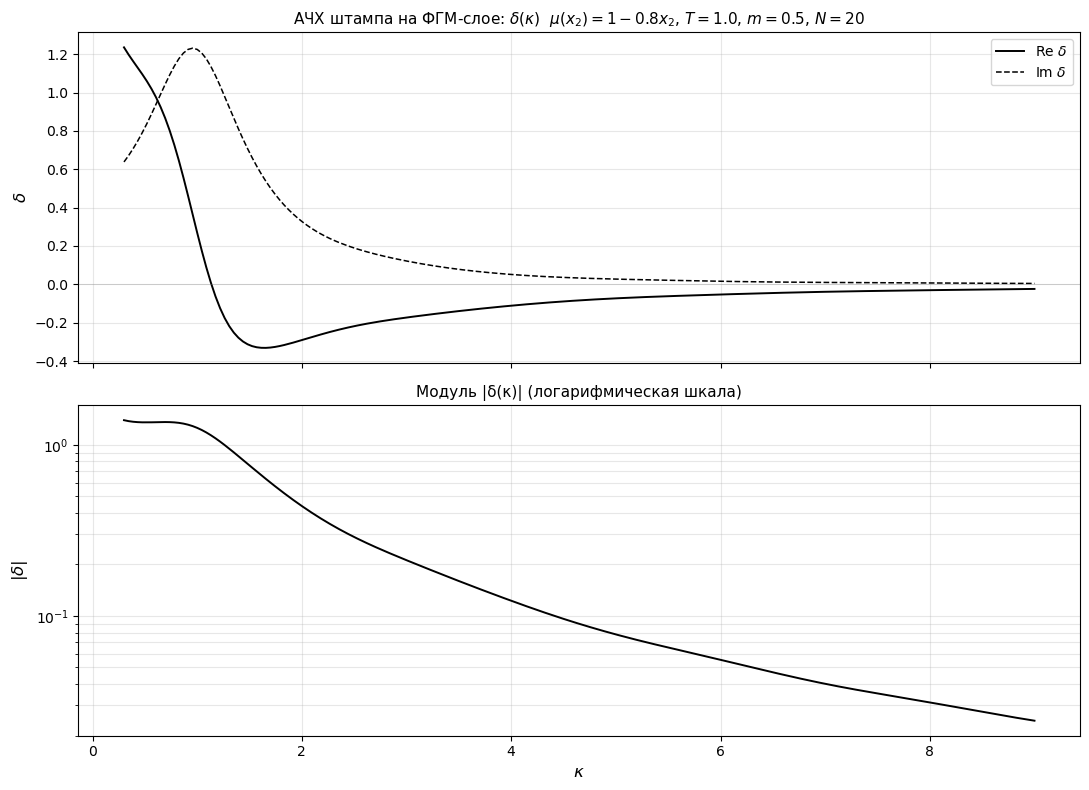

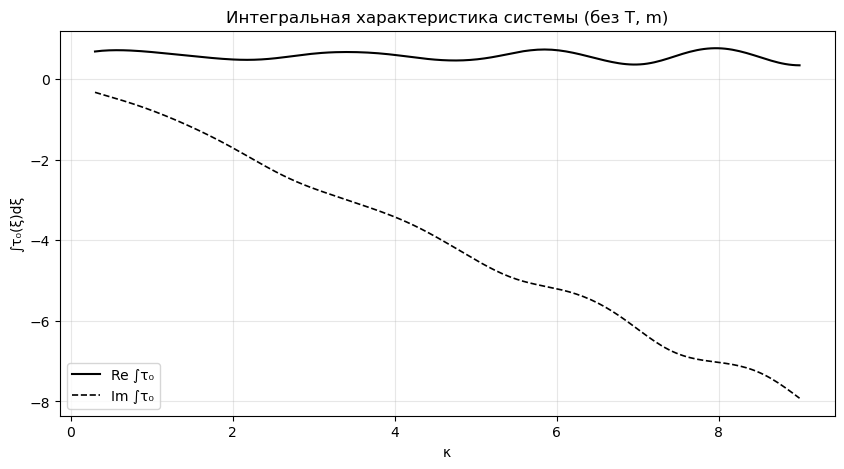

In [1]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=100, n_sub=20):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 1.0
    T = 1.0 + 0j
    mass = 0.5
    N = 20                                      

    # ---------- Диапазон частот ----------
    kappa_min = 0.3
    kappa_max = 9.0
    n_kappa = 200
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data1000.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()

АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1
  T = (1+0j),  m = 0.05,  N = 20,  a = 1.0
  κ ∈ [3.0, 5.0],  точек: 120
  Оценочное время ~720 секунд

  10/120  κ=3.151  δ=+1.987e-02+3.528e-01j  (237s, ост: 2607s)
  20/120  κ=3.319  δ=+1.365e-02+3.396e-01j  (471s, ост: 2356s)
  30/120  κ=3.487  δ=+6.497e-03+3.274e-01j  (704s, ост: 2111s)
  40/120  κ=3.655  δ=-9.851e-04+3.156e-01j  (940s, ост: 1880s)
  50/120  κ=3.824  δ=-8.867e-03+3.039e-01j  (1180s, ост: 1652s)
  60/120  κ=3.992  δ=-1.674e-02+2.917e-01j  (1403s, ост: 1403s)
  70/120  κ=4.160  δ=-2.400e-02+2.788e-01j  (1636s, ост: 1169s)
  80/120  κ=4.328  δ=-2.993e-02+2.652e-01j  (1870s, ост: 935s)
  90/120  κ=4.496  δ=-3.407e-02+2.516e-01j  (2098s, ост: 699s)
  100/120  κ=4.664  δ=-3.639e-02+2.387e-01j  (2326s, ост: 465s)
  110/120  κ=4.832  δ=-3.718e-02+2.268e-01j  (2556s, ост: 232s)
  120/120  κ=5.000  δ=-3.682e-02+2.164e-01j  (2786s, ост: 0s)

Готово за 2786.4 с (23.2 с/точку)
✓ Текстовая таблица успешно сохранена в afc_data1

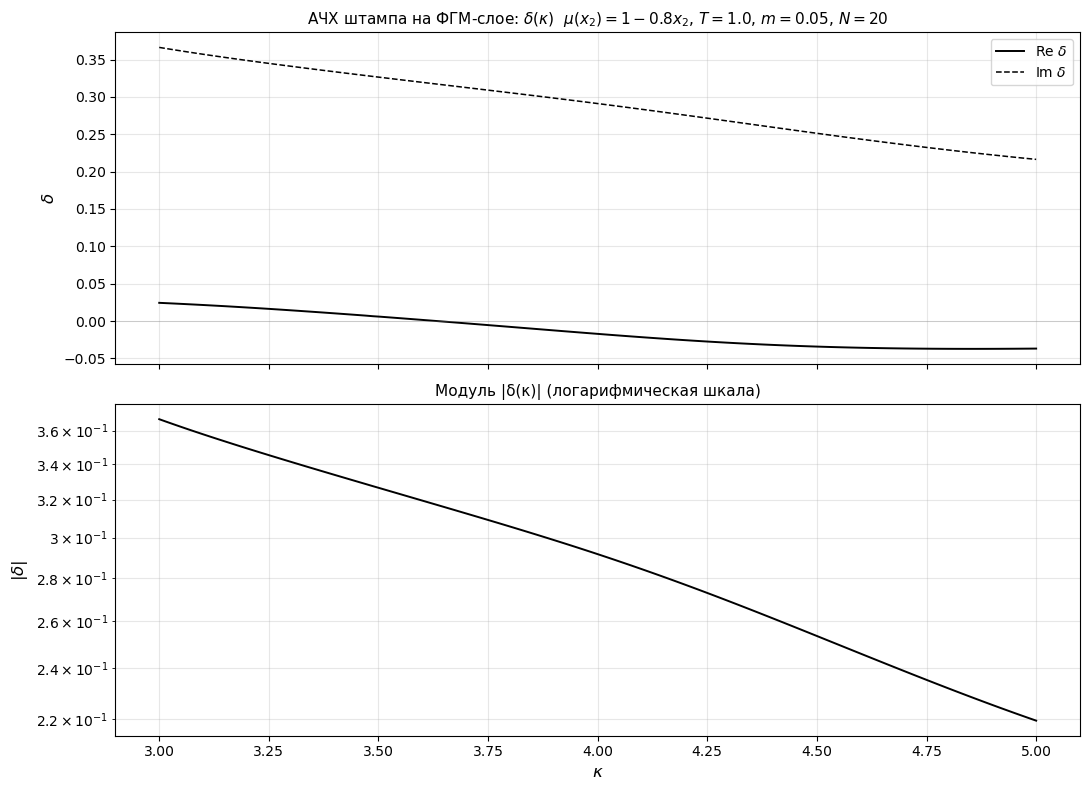

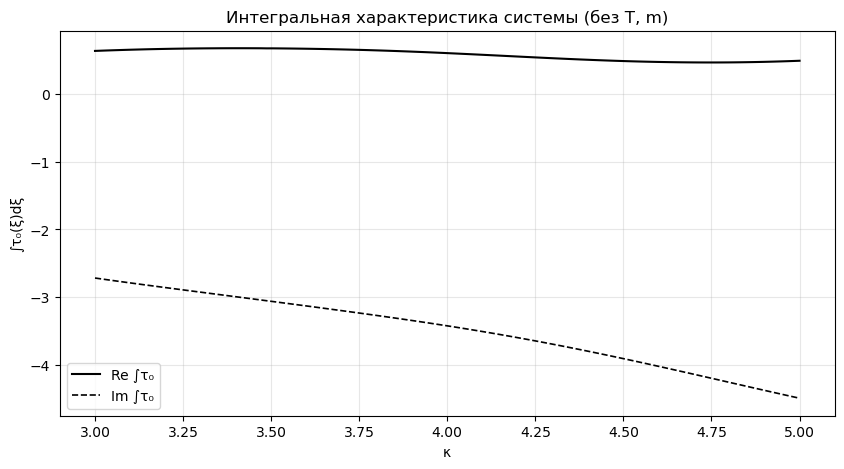

In [1]:
# -*- coding: utf-8 -*-
"""
амплитудно-частотная характеристика δ(κ) штампа на ФГМ-слое.

Для каждого κ из заданного диапазона:
1. Создаётся новый FGMLayer и Integral (\kappa зашит в обоих)
2. Собирается матрица МГЭ и решается СЛАУ для τ_0
3. По формуле δ = T / (∫τ_0 - m·κ²) считается смещение
4. Результат накапливается в массив δ(κ)
Строится график Re δ, Im δ 
Время: при N = 20 одно κ ≈ 5-10 секунд, для N_kappa сетка из 20-30 точек ≈ 7-10 минут.
для N = 40 и сетке N_kappa = 80 точность высокая, но и расчет долгий (примерно минут 30)
"""

import math
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import toeplitz
from kernel_fgm_A import FGMLayer, Integral


# =====================================================================
#  сборка и решение СЛАУ метода граничных элементов для нормированной задачи ∫−aak(x1−ξ) τ0(ξ) dξ=1\int_{-a}^a k(x_1-\xi)\,\tau_0(\xi)\,d\xi=1
# ∫{−a}{a}k(x1−ξ)τ0(ξ)dξ=1 (единичное смещение штампа)
# (J_vals = [integral.evaluate(u) ...] -- значения первообразной J(u) в этих точках. Каждое evaluate это 
# контурный интеграл с задачами Коши RK4 внутри. 
# Сборка первого столбца Тёплицевой матрицы c[0] = 2·J_vals[0] c[k] = J_vals[k]-J_vals[k-1]
#A = toeplitz(c, c) — матрица симметрично-Тёплицева
#solve(A, ones) - τ0
#τ0 - распределение контактных напряжений на единичное смещение.
# =====================================================================

def solve_tau0(integral, N, a_half):
    """Сборка матрицы + решение СЛАУ для нормированной задачи (RHS = 1)."""
    h = 2.0 * a_half / N
    ys = h * (np.arange(N) + 0.5)
    J_vals = np.array([integral.evaluate(float(u)) for u in ys])

    c = np.empty(N, dtype=complex)
    c[0] = 2.0 * J_vals[0]
    c[1:] = J_vals[1:] - J_vals[:-1]
    A = toeplitz(c, c)

    rhs = np.ones(N, dtype=complex)
    tau_0 = np.linalg.solve(A, rhs)
    return tau_0, h


# =====================================================================
# Одна точка АЧХ
# layer = FGMLayer(... epsilon=1e-3, n_steps=200) — слой на частоте \kappa
# с предельным поглощением
#ε=10−3 (сдвигает полюсы/точку ветвления с оси) и 200 шагами RK4 для задач Коши.
#alpha_end = 1.2·κ/√μ_min — верхний предел интегрирования по \alpha
# Полюсы (корни дисперсии) лежат в (\kappa,\ \kappa/\sqrt{\mu_{\min}})
# множитель 1.2 даёт 20% запаса за последним полюсом. То есть граница интеграла задаётся именно дисперсионной полосой
#afe_integrand — обёртка над K_over_alpha с защитой от inf/nan (возле полюсов и при больших \alpha
# где cosh/sinh переполняются) — возвращает 0j вместо краха
# integral = Integral(...) → solve_tau0 → τ0
# integral_tau_0 = 1j·h·Σ τ_0 — интеграл ∫τ0 dξ по формуле прямоугольников,
# ×i —  нормировка ядра.
# delta = T/(integral_tau_0 - m κ²) — уравнение движения штампа.
# =====================================================================

def compute_delta_at_kappa(kappa, mu_func, rho_func, a_half, N, T, mass,
                            epsilon=1e-4, n_steps=100, n_sub=20):
    """Возвращает δ и ∫τ_0 dξ для заданного κ."""
    layer = FGMLayer(mu_func=mu_func, rho_func=rho_func,
                     kappa=kappa, epsilon=epsilon, n_steps=n_steps)
    alpha_end = 1.2 * kappa / math.sqrt(layer.mu_min)

    def safe_integrand(alpha):
        try:
            K = layer.K_over_alpha(alpha)
            if not (math.isfinite(K.real) and math.isfinite(K.imag)):
                return 0j
            return K
        except (OverflowError, ValueError):
            return 0j

    integral = Integral(safe_integrand, kappa=kappa,
                        alpha_end=alpha_end, n_sub=n_sub)

    tau_0, h = solve_tau0(integral, N, a_half)

#     integral_tau_0 = h * np.sum(tau_0)
#     delta = T / (-integral_tau_0 - mass * kappa * kappa)
    integral_tau_0 = h * np.sum(tau_0)      # нормировка ядра: ∫τ0_физ = i·∫τ0_код
    delta = T / (integral_tau_0 - mass * kappa ** 2)
    return delta, integral_tau_0

# =====================================================================
# Main: сканирование по \kappa и построение АЧХ
# =====================================================================

def main():
    # ---------- Параметры ----------
    mu_func  = lambda x: 1.0 - 0.8 * x         # мягкий верх
    rho_func = lambda x: 1.0
    a_half = 1.0
    T = 1.0 + 0j
    mass = 0.05
    N = 20                                      

    # ---------- Диапазон частот ----------
    kappa_min = 3.0
    kappa_max = 5.0
    n_kappa = 120
    kappas = np.linspace(kappa_min, kappa_max, n_kappa)

    print(f"АЧХ: ФГМ-слой «мягкий верх», μ(x) = 1 - 0.8x, ρ = 1")
    print(f"  T = {T},  m = {mass},  N = {N},  a = {a_half}")
    print(f"  κ ∈ [{kappa_min}, {kappa_max}],  точек: {n_kappa}")
    print(f"  Оценочное время ~{n_kappa * 6} секунд\n")

    # ---------- Расчёт ----------
    deltas = np.zeros(n_kappa, dtype=complex)
    integrals = np.zeros(n_kappa, dtype=complex)

    t0 = time.time()
    for i, kappa in enumerate(kappas):
        delta_i, integral_i = compute_delta_at_kappa(
            kappa, mu_func, rho_func, a_half, N, T, mass)
        deltas[i] = delta_i
        integrals[i] = integral_i

        if (i + 1) % 10 == 0:
            elapsed = time.time() - t0
            eta = elapsed * (n_kappa - i - 1) / (i + 1)
            print(f"  {i+1}/{n_kappa}  κ={kappa:.3f}  "
                  f"δ={delta_i.real:+.3e}{delta_i.imag:+.3e}j  "
                  f"({elapsed:.0f}s, ост: {eta:.0f}s)")

    total = time.time() - t0
    print(f"\nГотово за {total:.1f} с ({total / n_kappa:.1f} с/точку)")


    # ---------- Сохраняем числовые данные ----------
    #  Текстовый 
    output_txt = 'afc_data1000_4.txt'
    with open(output_txt, 'w', encoding='utf-8') as f:
        f.write("# Результаты расчета АЧХ штампа на ФГМ-слое\n")
        f.write(f"# Параметры: N={N}, a={a_half}, m={mass}, T={T.real}\n")
        f.write("kappa\tdelta_Re\tdelta_Im\t|delta| (Amp)\n")
        
        for k, d in zip(kappas, deltas):
            amp = np.abs(d)
            f.write(f"{k:.4f}\t{d.real:.8e}\t{d.imag:.8e}\t{amp:.8e}\n")
            
    print(f"✓ Текстовая таблица успешно сохранена в {output_txt}")

    # ---------- Графики ----------
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

    # Верхний - Re и Im δ
    axes[0].plot(kappas, deltas.real, 'k-',  lw=1.4, label=r'Re $\delta$')
    axes[0].plot(kappas, deltas.imag, 'k--', lw=1.1, label=r'Im $\delta$')
    axes[0].axhline(0, color='gray', lw=0.4, alpha=0.5)
    axes[0].set_ylabel(r'$\delta$', fontsize=12)
    axes[0].set_title(
        rf'АЧХ штампа на ФГМ-слое: $\delta(\kappa)$  '
        rf'$\mu(x_2) = 1 - 0.8 x_2$, '
        rf'$T = {T.real}$, $m = {mass}$, $N = {N}$',
        fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='best')

    # Нижний - модуль на лог-шкале 
    axes[1].semilogy(kappas, np.abs(deltas), 'k-', lw=1.4)
    axes[1].set_xlabel(r'$\kappa$', fontsize=12)
    axes[1].set_ylabel(r'$|\delta|$', fontsize=12)
    axes[1].set_title('Модуль |δ(κ)| (логарифмическая шкала)', fontsize=11)
    axes[1].grid(True, alpha=0.3, which='both')

    plt.tight_layout()
#     plt.savefig('afc_delta.png', dpi=200, bbox_inches='tight')
#     print("✓ График сохранён в afc_delta.png")
    plt.show()
    

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(kappas, integrals.real, 'k-', lw=1.5, label='Re ∫τ₀')
    ax.plot(kappas, integrals.imag, 'k--', lw=1.2, label='Im ∫τ₀')
    ax.set_xlabel('κ'); ax.set_ylabel('∫τ₀(ξ)dξ')
    ax.set_title('Интегральная характеристика системы (без T, m)')
    ax.grid(True, alpha=0.3); ax.legend()
#     plt.savefig('integral_tau0.png', dpi=200)

if __name__ == "__main__":
    main()